# CSC2042S Assignment 1: Perceptron Image Classification

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from data_utils import (
    load_dataset,
    train_val_split,
    flatten_images,
    normalise
)
from perceptron import BinaryPerceptron, MultiClassPerceptron
from train_eval import train_model, evaluate_model, grid_search

## 1. Data Processing

The Simpsons-MNIST dataset contains images of 10 Simpsons characters in RGB and grayscale formats. The provided training data is divided into training and validation subsets, while the separate test set is kept untouched until final evaluation.

Each image is flattened into a one-dimensional feature vector so that it can be used as input to the perceptron.

In [2]:
X_rgb, y_rgb = load_dataset("DATA/train", mode="RGB")
X_gray, y_gray = load_dataset("DATA/train", mode="L")

print("RGB shape:", X_rgb.shape)
print("Grayscale shape:", X_gray.shape)
print("Labels shape:", y_rgb.shape)

RGB shape: (8000, 28, 28, 3)
Grayscale shape: (8000, 28, 28)
Labels shape: (8000,)


In [3]:
X_rgb_flat = X_rgb.reshape(X_rgb.shape[0], -1)
X_gray_flat = X_gray.reshape(X_gray.shape[0], -1)

print("Flattened RGB shape:", X_rgb_flat.shape)
print("Flattened grayscale shape:", X_gray_flat.shape)

Flattened RGB shape: (8000, 2352)
Flattened grayscale shape: (8000, 784)


### Training and validation split

The provided training set contains 8,000 images. I use 80% for model training and 20% for validation. A fixed random seed is used to make the split reproducible.

The separate test set is not used during model development or hyperparameter tuning.

In [4]:
X_rgb_train, y_rgb_train, X_rgb_val, y_rgb_val = train_val_split(
    X_rgb,
    y_rgb,
    val_fraction=0.2,
    random_state=42
)

X_gray_train, y_gray_train, X_gray_val, y_gray_val = train_val_split(
    X_gray,
    y_gray,
    val_fraction=0.2,
    random_state=42
)

print("RGB training:", X_rgb_train.shape, y_rgb_train.shape)
print("RGB validation:", X_rgb_val.shape, y_rgb_val.shape)

print("Grayscale training:", X_gray_train.shape, y_gray_train.shape)
print("Grayscale validation:", X_gray_val.shape, y_gray_val.shape)

RGB training: (6400, 28, 28, 3) (6400,)
RGB validation: (1600, 28, 28, 3) (1600,)
Grayscale training: (6400, 28, 28) (6400,)
Grayscale validation: (1600, 28, 28) (1600,)


## 2. Multi-Class Perceptron Implementation

The model uses an object-oriented one-vs-rest design. A `BinaryPerceptron` is responsible for distinguishing one class from all other classes.

The `MultiClassPerceptron` maintains 10 independent `BinaryPerceptron` objects, one for each Simpsons character. For class `c`, training labels are converted to binary values where class `c` is labelled 1 and all other classes are labelled 0.

For multiclass prediction, the raw score from each binary perceptron is calculated and the class with the highest score is selected.

In [5]:
rgb_model = MultiClassPerceptron(
    n_features=X_rgb_flat.shape[1],
    n_classes=10,
    learning_rate=0.01
)

print("Number of binary perceptrons:", len(rgb_model.perceptrons))
print("Weight matrix shape:", rgb_model.weights.shape)
print("Initial weight value:", rgb_model.weights[0, 0])

Number of binary perceptrons: 10
Weight matrix shape: (10, 2352)
Initial weight value: 0.1


## 3. Training

The training procedure processes each training example individually using the perceptron learning rule. The order of training examples is shuffled between epochs using a fixed random seed.

Two stopping criteria are considered:

1. Fixed number of epochs.
2. Early stopping based on validation accuracy.

Early stopping terminates training when validation accuracy fails to improve for a specified number of consecutive epochs.

In [7]:
X_rgb_train_flat = X_rgb_train.reshape(len(X_rgb_train), -1)
X_rgb_val_flat = X_rgb_val.reshape(len(X_rgb_val), -1)


demo_model = MultiClassPerceptron(
    n_features=X_rgb_train_flat.shape[1],
    n_classes=10,
    learning_rate=0.01
)

history = train_model(
    demo_model,
    X_rgb_train_flat,
    y_rgb_train,
    X_rgb_val_flat,
    y_rgb_val,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("Epochs run:", history["epochs_run"])
print("Stopped reason:", history["stopped_reason"])

Epochs run: 4
Stopped reason: early_stopping


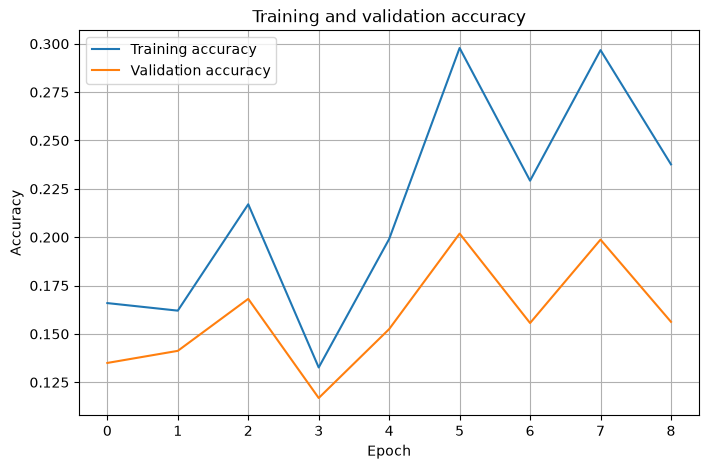

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["training_accuracy"],
    label="Training accuracy"
)

plt.plot(
    history["validation_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 4. Hyperparameter Tuning

The learning rate and input normalisation method were varied systematically using a grid search.

The learning rates tested were:

- 0.01
- 0.1
- 1.0

The normalisation methods tested were:

- None
- Min-max normalisation
- Z-score normalisation

The validation set was used to compare configurations. The test set was not used for hyperparameter selection.

In [ ]:

X_rgb_train_flat = X_rgb_train.reshape(len(X_rgb_train), -1)
X_rgb_val_flat = X_rgb_val.reshape(len(X_rgb_val), -1)

rgb_results = grid_search(
    X_rgb_train_flat,
    y_rgb_train,
    X_rgb_val_flat,
    y_rgb_val,
    n_features=X_rgb_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=10,
    stopping_criterion="fixed",
    random_state=42
)

for result in rgb_results:
    print(
        "Learning rate:", result["learning_rate"],
        "| Normalisation:", result["normalisation_method"],
        "| Validation accuracy:", result["val_accuracy"]
    )

Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
Learning rate: 0.01 | Normalisation: none | Validation accuracy: 0.135625
Learning rate: 0.1 | Normalisation: none | Validation accuracy: 0.143125
Learning rate: 1.0 | Normalisation: none | Validation accuracy: 0.178125
Learning rate: 0.01 | Normalisation: minmax | Validation accuracy: 0.20375
Learning rate: 0.1 | Normalisation: minmax | Validation accuracy: 0.20125
Learning rate: 1.0 | Normalisation: minmax | Validation accuracy: 0.143125
Learning rate: 0.01 | Normalisation: zscore | Validation accuracy: 0.1975
Learning rate: 0.1 | Normalisation: zscore | Validation accuracy: 0.184375
Learning rate: 1.0 | No

In [ ]:
best_rgb = max(
    rgb_results,
    key=lambda result: result["val_accuracy"]
)

print("Best RGB configuration")
print("----------------------")
print("Learning rate:", best_rgb["learning_rate"])
print("Normalisation:", best_rgb["normalisation_method"])
print("Validation accuracy:", best_rgb["val_accuracy"])

Best RGB configuration
----------------------
Learning rate: 0.01
Normalisation: minmax
Validation accuracy: 0.20375


### Grayscale hyperparameter search

The same hyperparameter grid was applied to the grayscale model. This allows the effect of colour information to be assessed independently from the hyperparameter selection process.

In [8]:
X_gray_train_flat = X_gray_train.reshape(len(X_gray_train), -1)
X_gray_val_flat = X_gray_val.reshape(len(X_gray_val), -1)

gray_results = grid_search(
    X_gray_train_flat,
    y_rgb_train,
    X_gray_val_flat,
    y_rgb_val,
    n_features=X_gray_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=10,
    stopping_criterion="fixed",
    random_state=42
)

for result in gray_results:
    print(
        "Learning rate:", result["learning_rate"],
        "| Normalisation:", result["normalisation_method"],
        "| Validation accuracy:", result["val_accuracy"]
    )

best_gray = max(
    gray_results,
    key=lambda result: result["val_accuracy"]
)

print("\nBest grayscale configuration")
print("----------------------------")
print("Learning rate:", best_gray["learning_rate"])
print("Normalisation:", best_gray["normalisation_method"])
print("Validation accuracy:", best_gray["val_accuracy"])

Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
Learning rate: 0.01 | Normalisation: none | Validation accuracy: 0.201875
Learning rate: 0.1 | Normalisation: none | Validation accuracy: 0.18375
Learning rate: 1.0 | Normalisation: none | Validation accuracy: 0.205625
Learning rate: 0.01 | Normalisation: minmax | Validation accuracy: 0.204375
Learning rate: 0.1 | Normalisation: minmax | Validation accuracy: 0.17625
Learning rate: 1.0 | Normalisation: minmax | Validation accuracy: 0.196875
Learning rate: 0.01 | Normalisation: zscore | Validation accuracy: 0.20875
Learning rate: 0.1 | Normalisation: zscore | Validation accuracy: 0.2125
Learning rate: 1.0 | Nor

### Hyperparameter effects

The following plots show how validation accuracy changes as the learning rate and normalisation method are varied.

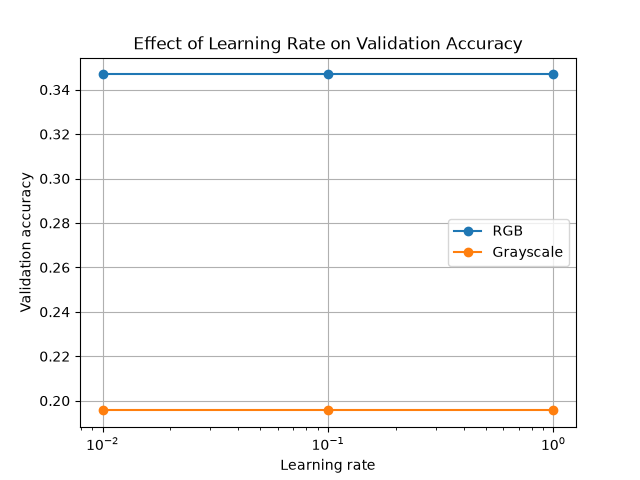

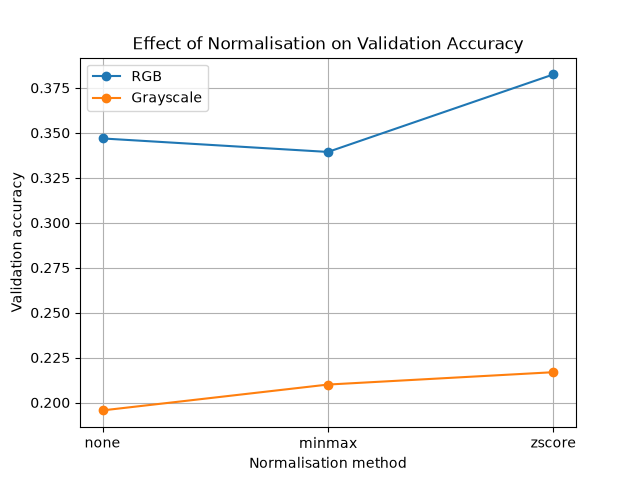

In [ ]:
from IPython.display import Image, display

display(Image(filename="learning_rate_comparison.png"))
display(Image(filename="normalisation_comparison.png"))

## 5. Final Evaluation

After selecting the best hyperparameters using the validation data, final RGB and grayscale models are trained.

The separate test set is only used at this stage. Accuracy, precision, recall, F1 score and confusion matrices are calculated for both models.

In [ ]:

X_rgb_test, y_rgb_test = load_dataset("DATA/test", mode="RGB")
X_gray_test, y_gray_test = load_dataset("DATA/test", mode="L")

X_rgb_test_flat = X_rgb_test.reshape(len(X_rgb_test), -1)
X_gray_test_flat = X_gray_test.reshape(len(X_gray_test), -1)

print("RGB test:", X_rgb_test_flat.shape)
print("Grayscale test:", X_gray_test_flat.shape)

RGB test: (2000, 2352)
Grayscale test: (2000, 784)


## 6. RGB vs Grayscale Analysis

The RGB model achieved substantially higher test accuracy than the grayscale model.

| Model | Test accuracy |
|---|---:|
| RGB | 37.5% |
| Grayscale | 19.3% |

The difference is 18.2 percentage points.

This indicates that colour information provides useful information for distinguishing the Simpsons characters. Some characters may have visually distinctive colours in their clothing, skin, hair or other features that are lost when the images are converted to grayscale.

However, the overall RGB accuracy is still relatively low. This suggests that the perceptron has limited ability to represent the complex visual decision boundaries required for this image classification problem.

In [ ]:
import numpy as np
from data_utils import load_dataset


X_rgb, y_rgb = load_dataset("DATA/train", mode="RGB")


X_rgb_test, y_rgb_test = load_dataset("DATA/test", mode="RGB")

print("RGB training shape:", X_rgb.shape)
print("RGB training labels:", y_rgb.shape)
print("RGB test shape:", X_rgb_test.shape)
print("RGB test labels:", y_rgb_test.shape)

RGB training shape: (8000, 28, 28, 3)
RGB training labels: (8000,)
RGB test shape: (2000, 28, 28, 3)
RGB test labels: (2000,)


In [ ]:

X_gray, y_gray = load_dataset("DATA/train", mode="L")


X_gray_test, y_gray_test = load_dataset("DATA/grayscale-test/test", mode="L")

print("Grayscale training shape:", X_gray.shape)
print("Grayscale training labels:", y_gray.shape)
print("Grayscale test shape:", X_gray_test.shape)
print("Grayscale test labels:", y_gray_test.shape)

Grayscale training shape: (8000, 28, 28)
Grayscale training labels: (8000,)
Grayscale test shape: (2000, 28, 28)
Grayscale test labels: (2000,)


In [ ]:
from data_utils import train_val_split


X_rgb_train, y_rgb_train, X_rgb_val, y_rgb_val = train_val_split(
    X_rgb,
    y_rgb,
    val_fraction=0.2,
    random_state=42
)


X_gray_train, y_gray_train, X_gray_val, y_gray_val = train_val_split(
    X_gray,
    y_gray,
    val_fraction=0.2,
    random_state=42
)

print("RGB training:", X_rgb_train.shape, y_rgb_train.shape)
print("RGB validation:", X_rgb_val.shape, y_rgb_val.shape)

print("Grayscale training:", X_gray_train.shape, y_gray_train.shape)
print("Grayscale validation:", X_gray_val.shape, y_gray_val.shape)

RGB training: (6400, 28, 28, 3) (6400,)
RGB validation: (1600, 28, 28, 3) (1600,)
Grayscale training: (6400, 28, 28) (6400,)
Grayscale validation: (1600, 28, 28) (1600,)


In [ ]:
X_rgb_train_flat = X_rgb_train.reshape(X_rgb_train.shape[0], -1)
X_rgb_val_flat = X_rgb_val.reshape(X_rgb_val.shape[0], -1)

X_gray_train_flat = X_gray_train.reshape(X_gray_train.shape[0], -1)
X_gray_val_flat = X_gray_val.reshape(X_gray_val.shape[0], -1)

print("RGB flattened training:", X_rgb_train_flat.shape)
print("RGB flattened validation:", X_rgb_val_flat.shape)

print("Grayscale flattened training:", X_gray_train_flat.shape)
print("Grayscale flattened validation:", X_gray_val_flat.shape)

RGB flattened training: (6400, 2352)
RGB flattened validation: (1600, 2352)
Grayscale flattened training: (6400, 784)
Grayscale flattened validation: (1600, 784)


## Task 2: Multi-class Perceptron

The classifier uses an object-oriented one-vs-rest design.

A `BinaryPerceptron` is created for each of the 10 Simpsons characters. Each binary perceptron learns to distinguish one class from all other classes.

The binary perceptrons initialise all weights and the bias to 0.1. For multiclass prediction, the raw score from each binary perceptron is calculated and the class with the highest score is selected.

In [ ]:
from perceptron import BinaryPerceptron, MultiClassPerceptron


binary_model = BinaryPerceptron(
    n_features=784,
    learning_rate=0.01
)

print("Binary weight shape:", binary_model.weights.shape)
print("Binary weight minimum:", binary_model.weights.min())
print("Binary weight maximum:", binary_model.weights.max())
print("Binary bias:", binary_model.bias)


multiclass_model = MultiClassPerceptron(
    n_features=784,
    n_classes=10,
    learning_rate=0.01
)

print("Number of binary perceptrons:", len(multiclass_model.perceptrons))
print("Multiclass weight shape:", multiclass_model.weights.shape)
print("Multiclass weight minimum:", multiclass_model.weights.min())
print("Multiclass weight maximum:", multiclass_model.weights.max())

Binary weight shape: (784,)
Binary weight minimum: 0.1
Binary weight maximum: 0.1
Binary bias: 0.1
Number of binary perceptrons: 10
Multiclass weight shape: (10, 784)
Multiclass weight minimum: 0.1
Multiclass weight maximum: 0.1


In [ ]:
X_toy = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [8, 8],
    [9, 8],
    [8, 9]
])

y_toy = np.array([0, 0, 0, 1, 1, 1])

toy_model = BinaryPerceptron(
    n_features=2,
    learning_rate=0.1
)

print("Predictions before training:")
print(toy_model.predict(X_toy))


for epoch in range(10):
    mistakes = toy_model.train(X_toy, y_toy)

print("Predictions after training:")
print(toy_model.predict(X_toy))

print("True labels:")
print(y_toy)

Predictions before training:
[1 1 1 1 1 1]
Predictions after training:
[0 0 0 1 1 1]
True labels:
[0 0 0 1 1 1]


In [ ]:
small_model = MultiClassPerceptron(
    n_features=784,
    n_classes=10,
    learning_rate=0.01
)


X_small = X_gray_train_flat[:200]
y_small = y_gray_train[:200]

small_model.train_epoch(
    X_small,
    y_small,
    rng=np.random.default_rng(42)
)


for class_id in range(10):
    predictions = small_model.perceptrons[class_id].predict(X_small)

    own_class_rate = predictions[y_small == class_id].mean()
    other_class_rate = predictions[y_small != class_id].mean()

    print(
        f"Class {class_id}: "
        f"own class = {own_class_rate:.3f}, "
        f"other classes = {other_class_rate:.3f}"
    )

Class 0: own class = 0.200, other classes = 0.011
Class 1: own class = 0.000, other classes = 0.000
Class 2: own class = 0.783, other classes = 0.333
Class 3: own class = 0.000, other classes = 0.000
Class 4: own class = 0.000, other classes = 0.000
Class 5: own class = 0.000, other classes = 0.005
Class 6: own class = 1.000, other classes = 0.823
Class 7: own class = 0.000, other classes = 0.000
Class 8: own class = 0.000, other classes = 0.000
Class 9: own class = 0.062, other classes = 0.000


## Task 3: Training and Stopping Criteria

The multiclass perceptron is trained one image at a time. Before each epoch, the training examples are shuffled using a fixed random seed to make the experiments reproducible.

Two stopping criteria are investigated:

1. **Fixed number of epochs:** training continues for a predetermined number of epochs.
2. **Early stopping:** training stops when validation accuracy has failed to improve for a specified number of consecutive epochs (`patience`).

Training and validation accuracy are recorded after every epoch to monitor convergence and overfitting.

In [ ]:
from train_eval import train_model



X_task3 = X_rgb_train_flat[:2000]
y_task3 = y_rgb_train[:2000]

X_val_task3 = X_rgb_val_flat[:500]
y_val_task3 = y_rgb_val[:500]

# Fixed number of epochs
fixed_model = MultiClassPerceptron(
    n_features=X_task3.shape[1],
    n_classes=10,
    learning_rate=0.01
)

fixed_history = train_model(
    fixed_model,
    X_task3,
    y_task3,
    X_val_task3,
    y_val_task3,
    max_epochs=10,
    stopping_criterion="fixed",
    random_state=42
)

# Early stopping
early_model = MultiClassPerceptron(
    n_features=X_task3.shape[1],
    n_classes=10,
    learning_rate=0.01
)

early_history = train_model(
    early_model,
    X_task3,
    y_task3,
    X_val_task3,
    y_val_task3,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("FIXED EPOCHS")
print("Epochs run:", fixed_history["epochs_run"])
print("Stopped reason:", fixed_history["stopped_reason"])
print("Final validation accuracy:",
      fixed_history["validation_accuracy"][-1])

print()

print("EARLY STOPPING")
print("Epochs run:", early_history["epochs_run"])
print("Stopped reason:", early_history["stopped_reason"])
print("Best validation accuracy:",
      max(early_history["validation_accuracy"]))

FIXED EPOCHS
Epochs run: 10
Stopped reason: max_epochs
Final validation accuracy: 0.118

EARLY STOPPING
Epochs run: 4
Stopped reason: early_stopping
Best validation accuracy: 0.138


## Task 3: Training Convergence

The validation accuracy is monitored after each epoch. Early stopping terminates training when validation performance no longer improves, while the fixed-epoch approach continues for the full predetermined number of epochs.

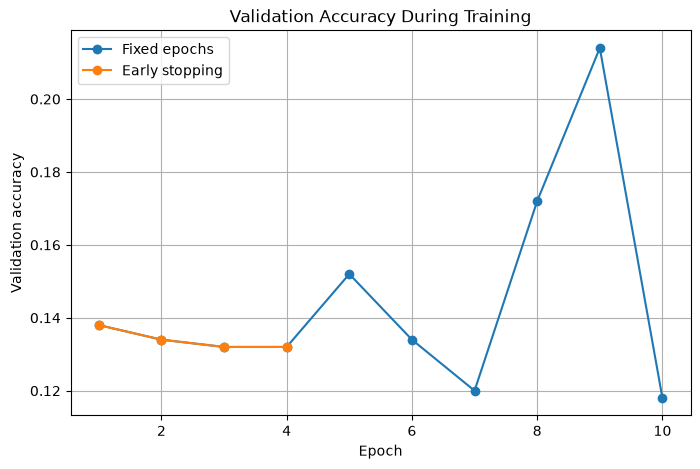

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(fixed_history["validation_accuracy"]) + 1),
    fixed_history["validation_accuracy"],
    marker="o",
    label="Fixed epochs"
)

plt.plot(
    range(1, len(early_history["validation_accuracy"]) + 1),
    early_history["validation_accuracy"],
    marker="o",
    label="Early stopping"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation Accuracy During Training")
plt.legend()
plt.grid(True)

plt.show()

## Task 4: Hyperparameter Tuning

The RGB and grayscale perceptrons are tuned separately using the validation set.

Two hyperparameters are investigated:

- Learning rate: 0.01, 0.1, and 1.0
- Input normalisation: none, min-max scaling to [0, 1], and z-score normalisation

A grid search is used to evaluate every combination. The test set is not used during hyperparameter selection. The combination with the highest validation accuracy is selected for each input modality.

In [ ]:
from train_eval import grid_search



rgb_results = grid_search(
    X_rgb_train_flat,
    y_rgb_train,
    X_rgb_val_flat,
    y_rgb_val,
    n_features=X_rgb_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=5,
    stopping_criterion="fixed",
    random_state=42
)


best_rgb = max(
    rgb_results,
    key=lambda result: result["val_accuracy"]
)

print("BEST RGB CONFIGURATION")
print("Learning rate:", best_rgb["learning_rate"])
print("Normalisation:", best_rgb["normalisation_method"])
print("Validation accuracy:", best_rgb["val_accuracy"])

Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
BEST RGB CONFIGURATION
Learning rate: 0.1
Normalisation: zscore
Validation accuracy: 0.213125


In [ ]:
gray_results = grid_search(
    X_gray_train_flat,
    y_gray_train,
    X_gray_val_flat,
    y_gray_val,
    n_features=X_gray_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=5,
    stopping_criterion="fixed",
    random_state=42
)


best_gray = max(
    gray_results,
    key=lambda result: result["val_accuracy"]
)

print("BEST GRAYSCALE CONFIGURATION")
print("Learning rate:", best_gray["learning_rate"])
print("Normalisation:", best_gray["normalisation_method"])
print("Validation accuracy:", best_gray["val_accuracy"])

Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
BEST GRAYSCALE CONFIGURATION
Learning rate: 0.01
Normalisation: zscore
Validation accuracy: 0.2075


## Task 4: Hyperparameter Search Results

The grid search evaluated three learning rates (0.01, 0.1, and 1.0) combined with three normalisation methods (none, min-max, and z-score).

For the RGB model, the best validation performance was obtained using a learning rate of 0.1 with z-score normalisation, achieving 21.31% validation accuracy.

For the grayscale model, the best validation performance was obtained using a learning rate of 0.01 with z-score normalisation, achieving 20.75% validation accuracy.

These settings will be used for the final models in Task 5.

In [ ]:
import pandas as pd

# Create a table of all RGB grid-search results
rgb_grid_table = pd.DataFrame([
    {
        "Learning rate": r["learning_rate"],
        "Normalisation": r["normalisation_method"],
        "Validation accuracy": r["val_accuracy"]
    }
    for r in rgb_results
])

print("RGB GRID SEARCH RESULTS")
display(rgb_grid_table)

print("\nGRAYSCALE GRID SEARCH RESULTS")

gray_grid_table = pd.DataFrame([
    {
        "Learning rate": r["learning_rate"],
        "Normalisation": r["normalisation_method"],
        "Validation accuracy": r["val_accuracy"]
    }
    for r in gray_results
])

display(gray_grid_table)

RGB GRID SEARCH RESULTS


,Learning rate,Normalisation,Validation accuracy
0,0.01,none,0.158750
1,0.10,none,0.124375
2,1.00,none,0.113750
3,0.01,minmax,0.106250
4,0.10,minmax,0.159375
5,1.00,minmax,0.130625
6,0.01,zscore,0.193750
7,0.10,zscore,0.213125
8,1.00,zscore,0.171875



GRAYSCALE GRID SEARCH RESULTS


,Learning rate,Normalisation,Validation accuracy
0,0.01,none,0.158750
1,0.10,none,0.124375
2,1.00,none,0.113750
3,0.01,minmax,0.161875
4,0.10,minmax,0.157500
5,1.00,minmax,0.150000
6,0.01,zscore,0.207500
7,0.10,zscore,0.197500
8,1.00,zscore,0.181875


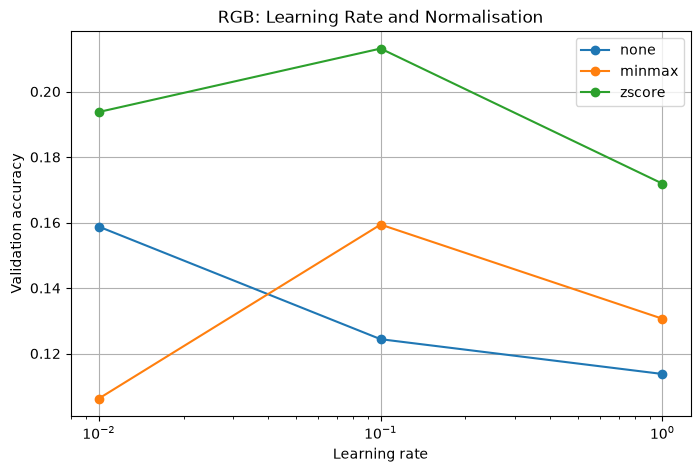

In [ ]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

for method in ["none", "minmax", "zscore"]:
    values = [
        r["val_accuracy"]
        for r in rgb_results
        if r["normalisation_method"] == method
    ]

    learning_rates = [0.01, 0.1, 1.0]

    plt.plot(
        learning_rates,
        values,
        marker="o",
        label=method
    )

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.title("RGB: Learning Rate and Normalisation")
plt.legend()
plt.grid(True)

plt.show()

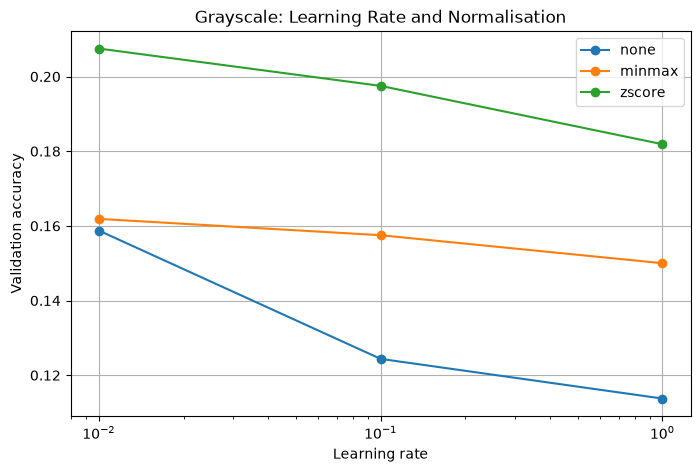

In [ ]:

plt.figure(figsize=(8, 5))

for method in ["none", "minmax", "zscore"]:
    values = [
        r["val_accuracy"]
        for r in gray_results
        if r["normalisation_method"] == method
    ]

    learning_rates = [0.01, 0.1, 1.0]

    plt.plot(
        learning_rates,
        values,
        marker="o",
        label=method
    )

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.title("Grayscale: Learning Rate and Normalisation")
plt.legend()
plt.grid(True)

plt.show()

## Task 5: Final Evaluation

The final RGB and grayscale perceptrons are trained using the best hyperparameters selected from the validation-set grid search.

The RGB model uses a learning rate of 0.1 with z-score normalisation. The grayscale model uses a learning rate of 0.01 with z-score normalisation.

The held-out test set is used only at this stage for final evaluation. Accuracy, precision, recall, F1-score, and confusion matrices are calculated for both models.

In [ ]:
from data_utils import normalise


X_rgb_train_final, rgb_stats = normalise(
    X_rgb_train_flat,
    method="zscore"
)

X_rgb_val_final, _ = normalise(
    X_rgb_val_flat,
    method="zscore",
    stats=rgb_stats
)

X_rgb_test_final, _ = normalise(
    X_rgb_test_flat,
    method="zscore",
    stats=rgb_stats
)


X_gray_train_final, gray_stats = normalise(
    X_gray_train_flat,
    method="zscore"
)

X_gray_val_final, _ = normalise(
    X_gray_val_flat,
    method="zscore",
    stats=gray_stats
)

X_gray_test_final, _ = normalise(
    X_gray_test_flat,
    method="zscore",
    stats=gray_stats
)

print("RGB final training:", X_rgb_train_final.shape)
print("RGB final validation:", X_rgb_val_final.shape)
print("RGB final test:", X_rgb_test_final.shape)

print("Grayscale final training:", X_gray_train_final.shape)
print("Grayscale final validation:", X_gray_val_final.shape)
print("Grayscale final test:", X_gray_test_final.shape)

RGB final training: (6400, 2352)
RGB final validation: (1600, 2352)
RGB final test: (2000, 2352)
Grayscale final training: (6400, 784)
Grayscale final validation: (1600, 784)
Grayscale final test: (2000, 784)


In [ ]:
from perceptron import MultiClassPerceptron
from train_eval import train_model, evaluate_model


rgb_model = MultiClassPerceptron(
    n_features=X_rgb_train_final.shape[1],
    n_classes=10,
    learning_rate=0.1
)


rgb_history = train_model(
    rgb_model,
    X_rgb_train_final,
    y_rgb_train,
    X_rgb_val_final,
    y_rgb_val,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("RGB final model")
print("Epochs run:", rgb_history["epochs_run"])
print("Stopped reason:", rgb_history["stopped_reason"])
print("Best validation accuracy:",
      max(rgb_history["validation_accuracy"]))

RGB final model
Epochs run: 7
Stopped reason: early_stopping
Best validation accuracy: 0.21375


In [ ]:

grayscale_model = MultiClassPerceptron(
    n_features=X_gray_train_final.shape[1],
    n_classes=10,
    learning_rate=0.01
)

grayscale_history = train_model(
    grayscale_model,
    X_gray_train_final,
    y_gray_train,
    X_gray_val_final,
    y_gray_val,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("Grayscale final model")
print("Epochs run:", grayscale_history["epochs_run"])
print("Stopped reason:", grayscale_history["stopped_reason"])
print("Best validation accuracy:",
      max(grayscale_history["validation_accuracy"]))

Grayscale final model
Epochs run: 7
Stopped reason: early_stopping
Best validation accuracy: 0.220625


In [ ]:
rgb_val_result = evaluate_model(
    rgb_model,
    X_rgb_val_final,
    y_rgb_val,
    n_classes=10
)

rgb_test_result = evaluate_model(
    rgb_model,
    X_rgb_test_final,
    y_rgb_test,
    n_classes=10
)

print("RGB VALIDATION ACCURACY:",
      rgb_val_result["accuracy"])

print("RGB TEST ACCURACY:",
      rgb_test_result["accuracy"])

print("\nRGB TEST PRECISION:")
print(rgb_test_result["precision"])

print("\nRGB TEST RECALL:")
print(rgb_test_result["recall"])

print("\nRGB TEST F1:")
print(rgb_test_result["f1"])

RGB VALIDATION ACCURACY: 0.1725
RGB TEST ACCURACY: 0.1725

RGB TEST PRECISION:
[0.21582734 0.18539326 0.18131868 0.165      0.1420765  0.10344828
 0.23423423 0.128      0.17981073 0.18478261]

RGB TEST RECALL:
[0.15  0.165 0.165 0.165 0.13  0.075 0.26  0.16  0.285 0.17 ]

RGB TEST F1:
[0.17699115 0.17460317 0.17277487 0.165      0.13577023 0.08695652
 0.2464455  0.14222222 0.2205029  0.17708333]


In [ ]:
grayscale_val_result = evaluate_model(
    grayscale_model,
    X_gray_val_final,
    y_gray_val,
    n_classes=10
)

grayscale_test_result = evaluate_model(
    grayscale_model,
    X_gray_test_final,
    y_gray_test,
    n_classes=10
)

print("GRAYSCALE VALIDATION ACCURACY:",
      grayscale_val_result["accuracy"])

print("GRAYSCALE TEST ACCURACY:",
      grayscale_test_result["accuracy"])

print("\nGRAYSCALE TEST PRECISION:")
print(grayscale_test_result["precision"])

print("\nGRAYSCALE TEST RECALL:")
print(grayscale_test_result["recall"])

print("\nGRAYSCALE TEST F1:")
print(grayscale_test_result["f1"])

GRAYSCALE VALIDATION ACCURACY: 0.185
GRAYSCALE TEST ACCURACY: 0.1815

GRAYSCALE TEST PRECISION:
[0.26666667 0.19742489 0.19444444 0.11922141 0.17567568 0.29411765
 0.19135802 0.20689655 0.15151515 0.18471338]

GRAYSCALE TEST RECALL:
[0.12  0.23  0.175 0.245 0.195 0.15  0.31  0.12  0.125 0.145]

GRAYSCALE TEST F1:
[0.16551724 0.21247113 0.18421053 0.1603928  0.18483412 0.1986755
 0.23664122 0.15189873 0.1369863  0.16246499]


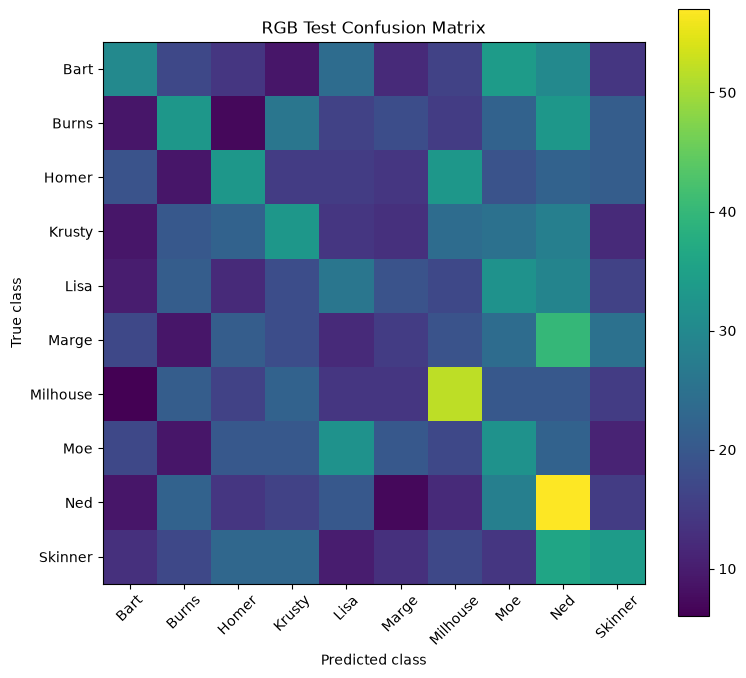

In [ ]:
import matplotlib.pyplot as plt

class_names = [
    "Bart",
    "Burns",
    "Homer",
    "Krusty",
    "Lisa",
    "Marge",
    "Milhouse",
    "Moe",
    "Ned",
    "Skinner"
]

plt.figure(figsize=(8, 7))
plt.imshow(rgb_test_result["confusion_matrix"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("RGB Test Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.tight_layout()
plt.show()

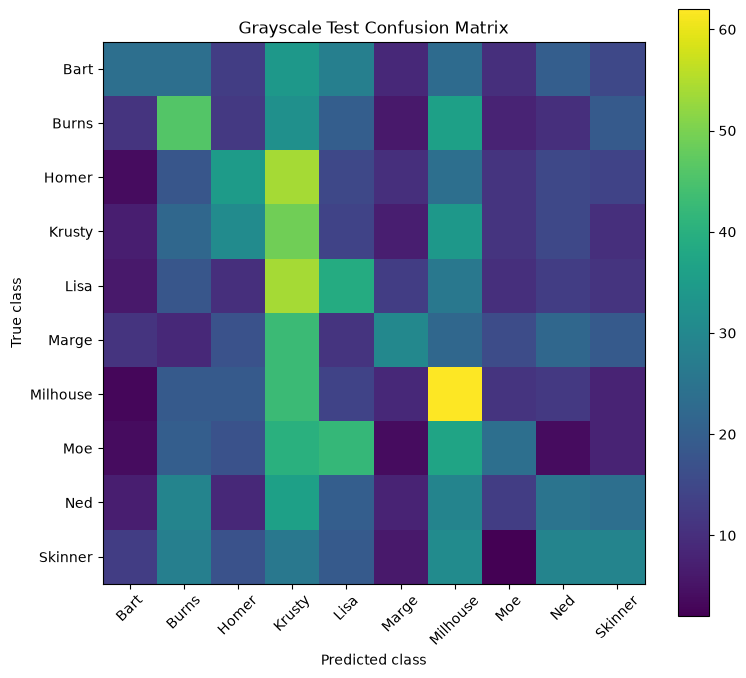

In [ ]:
plt.figure(figsize=(8, 7))
plt.imshow(grayscale_test_result["confusion_matrix"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Grayscale Test Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.tight_layout()
plt.show()

## Task 6: RGB vs Grayscale Analysis

The final RGB and grayscale models are compared using their test-set performance and per-class metrics. The confusion matrices are also examined to identify which Simpsons characters are classified reliably and which are frequently confused with other characters.

In [ ]:
print("RGB test accuracy:", rgb_test_result["accuracy"])
print("Grayscale test accuracy:", grayscale_test_result["accuracy"])

difference = (
    rgb_test_result["accuracy"]
    - grayscale_test_result["accuracy"]
)

print("RGB - Grayscale difference:", difference)

RGB test accuracy: 0.1725
Grayscale test accuracy: 0.1815
RGB - Grayscale difference: -0.009000000000000008


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Character": class_names,
    "RGB Precision": rgb_test_result["precision"],
    "RGB Recall": rgb_test_result["recall"],
    "RGB F1": rgb_test_result["f1"],
    "Grayscale Precision": grayscale_test_result["precision"],
    "Grayscale Recall": grayscale_test_result["recall"],
    "Grayscale F1": grayscale_test_result["f1"]
})

display(comparison)

,Character,RGB Precision,RGB Recall,RGB F1,Grayscale Precision,Grayscale Recall,Grayscale F1
0,Bart,0.215827,0.150,0.176991,0.266667,0.120,0.165517
1,Burns,0.185393,0.165,0.174603,0.197425,0.230,0.212471
2,Homer,0.181319,0.165,0.172775,0.194444,0.175,0.184211
3,Krusty,0.165000,0.165,0.165000,0.119221,0.245,0.160393
4,Lisa,0.142077,0.130,0.135770,0.175676,0.195,0.184834
5,Marge,0.103448,0.075,0.086957,0.294118,0.150,0.198675
6,Milhouse,0.234234,0.260,0.246445,0.191358,0.310,0.236641
7,Moe,0.128000,0.160,0.142222,0.206897,0.120,0.151899
8,Ned,0.179811,0.285,0.220503,0.151515,0.125,0.136986
9,Skinner,0.184783,0.170,0.177083,0.184713,0.145,0.162465


In [ ]:
rgb_f1 = rgb_test_result["f1"]
gray_f1 = grayscale_test_result["f1"]

best_rgb_class = class_names[np.argmax(rgb_f1)]
worst_rgb_class = class_names[np.argmin(rgb_f1)]

best_gray_class = class_names[np.argmax(gray_f1)]
worst_gray_class = class_names[np.argmin(gray_f1)]

print("Best RGB class:", best_rgb_class,
      "F1 =", rgb_f1.max())

print("Weakest RGB class:", worst_rgb_class,
      "F1 =", rgb_f1.min())

print("Best grayscale class:", best_gray_class,
      "F1 =", gray_f1.max())

print("Weakest grayscale class:", worst_gray_class,
      "F1 =", gray_f1.min())

Best RGB class: Milhouse F1 = 0.24644549763033174
Weakest RGB class: Marge F1 = 0.08695652173913043
Best grayscale class: Milhouse F1 = 0.2366412213740458
Weakest grayscale class: Ned F1 = 0.136986301369863


The grayscale model slightly outperformed the RGB model on the test set. The RGB model achieved an accuracy of 17.25%, while the grayscale model achieved 18.15%, giving grayscale an advantage of 0.90 percentage points.

The per-class results show that RGB did not consistently improve classification. Milhouse was the strongest RGB class, with an F1-score of 0.246, while Marge was the weakest with an F1-score of 0.087. For grayscale, Milhouse was also the strongest class, with an F1-score of 0.237, while Ned was the weakest with an F1-score of 0.137.

Some characters performed better with RGB, while others performed better with grayscale. For example, RGB achieved higher F1-scores for Milhouse, Ned and Skinner, whereas grayscale performed better for Burns, Homer, Lisa, Marge and Moe.

Overall, the results suggest that colour information did not provide a clear advantage for this perceptron on this dataset. The grayscale model performed slightly better overall, although the difference was small. This suggests that the character information contained in the images can often be captured from intensity and shape information without requiring the additional RGB channels. The relatively low accuracy of both models also indicates that the simple linear decision boundaries of the perceptron are not particularly effective for this image-classification problem..

## Task 7: Data Augmentation Analysis

The best RGB hyperparameters from Task 4 were reused for the augmentation experiments: a learning rate of 0.1 and z-score normalisation.

Three conditions were compared: no augmentation, brightness jitter, and small random rotations. For each condition, five models were trained using different random seeds. The augmented conditions doubled the training set from 6,400 to 12,800 images.

Test-set accuracy was recorded for each run, and the mean and standard deviation were calculated across the five seeds.

### Analysis

The baseline model without augmentation achieved a mean test accuracy of 36.15% with a standard deviation of 1.52% across the five random seeds.

Brightness augmentation produced the best result, with a mean test accuracy of 37.30% and a standard deviation of 0.93%. This represents an improvement of 1.15 percentage points over the baseline. The lower standard deviation also indicates that the brightness-augmented model was somewhat more consistent across different training seeds.

Rotation augmentation achieved a mean test accuracy of 36.17% with a standard deviation of 0.73%. This was almost identical to the baseline, with an improvement of only 0.02 percentage points.

The results suggest that brightness jitter was useful because it changes the overall lighting of an image while preserving the character's shape, position and colour relationships. This can expose the perceptron to slightly different lighting conditions without substantially changing the underlying character.

In contrast, the small rotations did not improve performance. Rotating an image changes the spatial position of many pixels, which may make the augmented examples less similar to the patterns learned by the linear perceptron. A small rotation may therefore introduce variation without providing useful additional information for this model.

These results also show that adding more data does not automatically produce a better model. The augmented training sets contained twice as many images, but only brightness augmentation produced a meaningful improvement. The usefulness of synthetic data depends on whether the transformation creates realistic variations that preserve the features needed for classification.